# Theo dõi huấn luyện — TensorBoard

Notebook riêng để xem events đã ghi, không train/evaluate hoặc tải model.
Chạy bằng kernel .venv. Các cell đầu đọc trực tiếp events và vẽ biểu đồ;
phần cuối khởi động dashboard live và có đường dẫn mở tab riêng.
Chỉ run có events xuất hiện; hiện có lan_2/lan_3. Không tạo log giả từ history.json.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
from IPython.display import display, HTML

cwd = Path.cwd().resolve()
project = cwd if (cwd / 'src' / '2_train.py').exists() else cwd / 'practice_2_pretrained_model'
LOGDIR = project / 'outputs' / 'runs'
PORT = 6006
runs = [folder for folder in sorted(LOGDIR.glob('lan_*'))
        if list((folder / 'tensorboard').glob('events.out.tfevents.*'))]
print('Logdir:', LOGDIR)
print('Runs có events:', [folder.name for folder in runs])
if not runs:
    print('Chưa có events. Không cần train lại để xem báo cáo: dùng Practice_2_Report.ipynb.')


Logdir: D:\newtask\DL\practice_2_pretrained_model\outputs\runs
Runs có events: ['lan_2', 'lan_3']


## Xem trực tiếp từ file events

Biểu đồ dưới đây không cần server hoặc iframe. Chạy lại cell để đọc events mới;
để tự làm mới liên tục, dùng dashboard live ở phần tiếp theo.


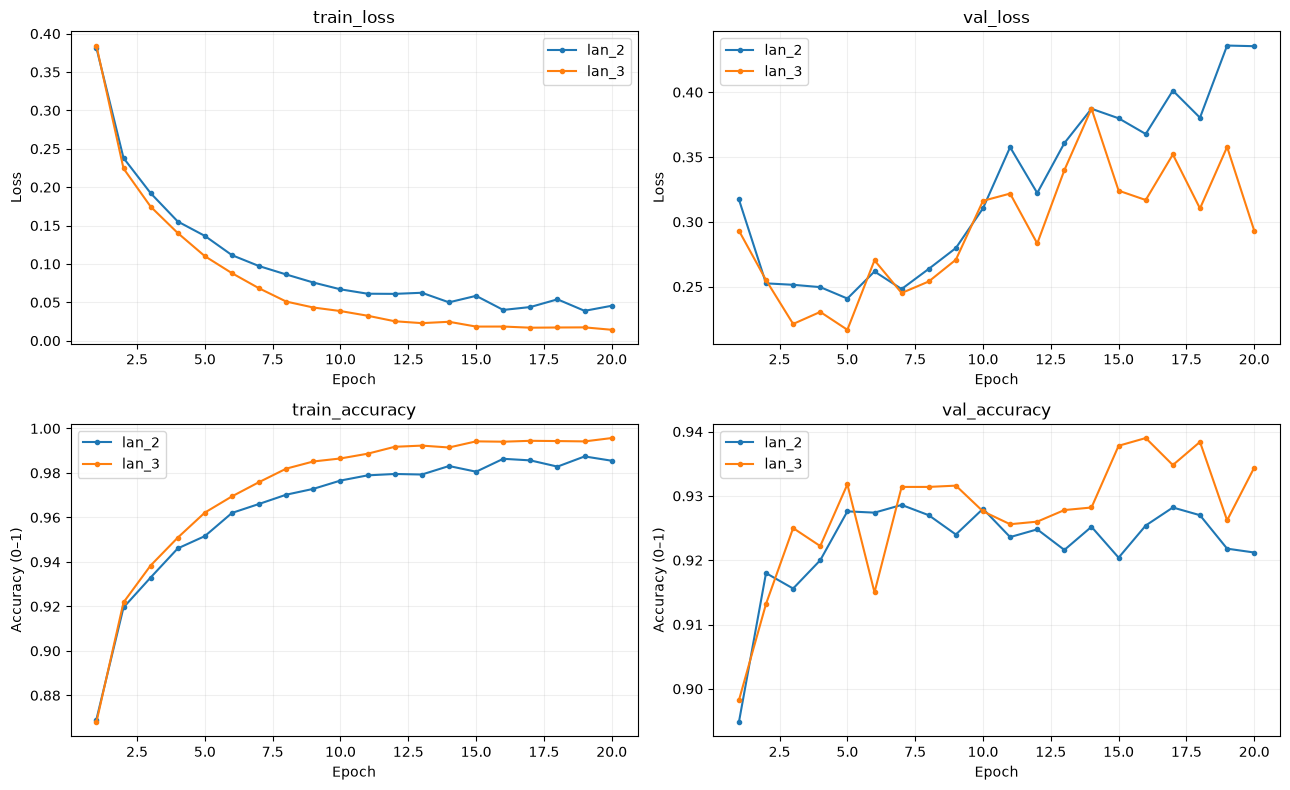

In [2]:
metrics = ['train_loss', 'val_loss', 'train_accuracy', 'val_accuracy']
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for folder in runs:
    accumulator = EventAccumulator(str(folder / 'tensorboard'), size_guidance={'scalars': 0})
    accumulator.Reload()
    for ax, tag in zip(axes.flat, metrics):
        if tag not in accumulator.Tags()['scalars']:
            continue
        # Resumed event files may repeat a step; keep the newest wall-time value.
        by_step = {}
        for event in sorted(accumulator.Scalars(tag), key=lambda item: item.wall_time):
            by_step[event.step] = event.value
        steps = sorted(by_step)
        ax.plot(steps, [by_step[step] for step in steps], marker='.', label=folder.name)
for ax, tag in zip(axes.flat, metrics):
    ax.set(title=tag, xlabel='Epoch', ylabel='Accuracy (0–1)' if 'accuracy' in tag else 'Loss')
    ax.grid(alpha=.2)
    if ax.lines:
        ax.legend()
plt.tight_layout(); plt.show()


## Dashboard live

Chạy cell này để khởi động TensorBoard. Mở link ở tab trình duyệt nếu VS Code
không hiển thị dashboard nhúng. Trong TensorBoard, Settings → bật tự refresh
để xem events mới; số liệu chỉ thay đổi khi chương trình train ghi log.
Nếu cổng6006 đang dùng cho project khác, đổi PORT rồi chạy lại hai cell cuối.


In [3]:
import json
import subprocess
import sys
import time
import urllib.request
import urllib.error

URL = f'http://127.0.0.1:{PORT}'
if runs:
    ready = False
    try:
        with urllib.request.urlopen(URL + '/data/logdir', timeout=2) as response:
            data = json.load(response)
        existing_logdir = data['logdir'] if isinstance(data, dict) else data
        if Path(existing_logdir).resolve() != LOGDIR.resolve():
            raise ValueError('Cổng đang phục vụ project khác. Đổi PORT và chạy lại.')
        ready = True
    except (urllib.error.URLError, TimeoutError):
        pass
    if not ready:
        server_log = project / 'outputs' / 'tensorboard_server.log'
        with server_log.open('a', encoding='utf-8') as output:
            TB_PROCESS = subprocess.Popen(
                [sys.executable, '-m', 'tensorboard.main', '--logdir', str(LOGDIR),
                 '--host', '127.0.0.1', '--port', str(PORT), '--reload_interval', '5'],
                stdout=output, stderr=subprocess.STDOUT,
                creationflags=getattr(subprocess, 'CREATE_NO_WINDOW', 0))
        for _ in range(120):
            try:
                with urllib.request.urlopen(URL + '/data/plugin/scalars/tags', timeout=1) as response:
                    ready = bool(json.load(response))
                if ready:
                    break
            except (urllib.error.URLError, TimeoutError):
                pass
            time.sleep(0.25)
        if not ready:
            raise RuntimeError(f'TensorBoard chưa sẵn sàng. Xem {server_log}')
    print('TensorBoard ready:', URL, '| logdir:', LOGDIR)
    display(HTML(f'<a href="{URL}/#scalars" target="_blank">Mở TensorBoard ở tab riêng</a>'))
else:
    print('Không khởi động dashboard vì chưa có events.')


TensorBoard ready: http://127.0.0.1:6006 | logdir: D:\newtask\DL\practice_2_pretrained_model\outputs\runs


In [4]:
from IPython.display import IFrame

if runs:
    display(IFrame(src=URL + '/#scalars', width='100%', height=800))
